In [23]:
import time

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("archive/ecommerceDataset.csv",header=None, names=["category", "description"])
df = df.dropna()
df = df.drop_duplicates()

In [24]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["description"],
    df["category"],
    test_size=0.2,
    random_state=42,
    stratify=df["category"],
)

In [26]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_features=30000,
    sublinear_tf=True,
)
X_train = vectorizer.fit_transform(X_train_txt)
X_test = vectorizer.transform(X_test_txt)
print("\nMatrice TF-IDF train:", X_train.shape)


Matrice TF-IDF train: (22241, 30000)


In [27]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Complement Naive Bayes": ComplementNB(alpha=0.1),
    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
    ),
}

In [28]:
results = []
predictions = {}
 
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - t0
 
    t0 = time.time()
    y_pred = model.predict(X_test)
    pred_time = time.time() - t0
 
    predictions[name] = y_pred
    results.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "F1 macro": f1_score(y_test, y_pred, average="macro"),
            "Timp antrenare (s)": train_time,
            "Timp predictie (s)": pred_time,
        }
    )
 
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, y_pred, digits=4))
 
results_df = pd.DataFrame(results).set_index("Model").round(4)
print("\n\nCOMPARATIE FINALA\n", results_df)


Multinomial Naive Bayes
                        precision    recall  f1-score   support

                 Books     0.9694    0.9113    0.9394      1251
Clothing & Accessories     0.9617    0.9727    0.9671      1135
           Electronics     0.9219    0.9331    0.9275      1062
             Household     0.9315    0.9531    0.9422      2113

              accuracy                         0.9439      5561
             macro avg     0.9461    0.9426    0.9441      5561
          weighted avg     0.9444    0.9439    0.9439      5561


Complement Naive Bayes
                        precision    recall  f1-score   support

                 Books     0.9616    0.9209    0.9408      1251
Clothing & Accessories     0.9555    0.9833    0.9692      1135
           Electronics     0.9260    0.9313    0.9286      1062
             Household     0.9436    0.9498    0.9467      2113

              accuracy                         0.9466      5561
             macro avg     0.9467    0.9463    0.9

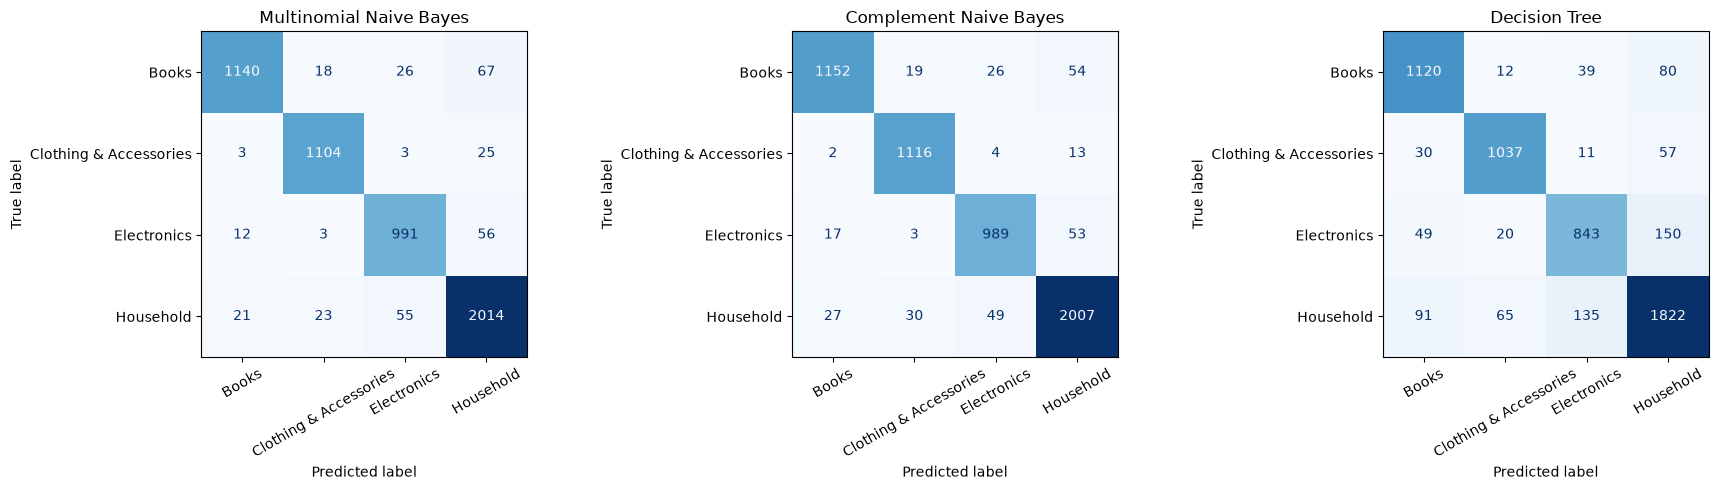

In [29]:
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, ax=ax, xticks_rotation=30, colorbar=False, cmap="Blues"
    )
    ax.set_title(name)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

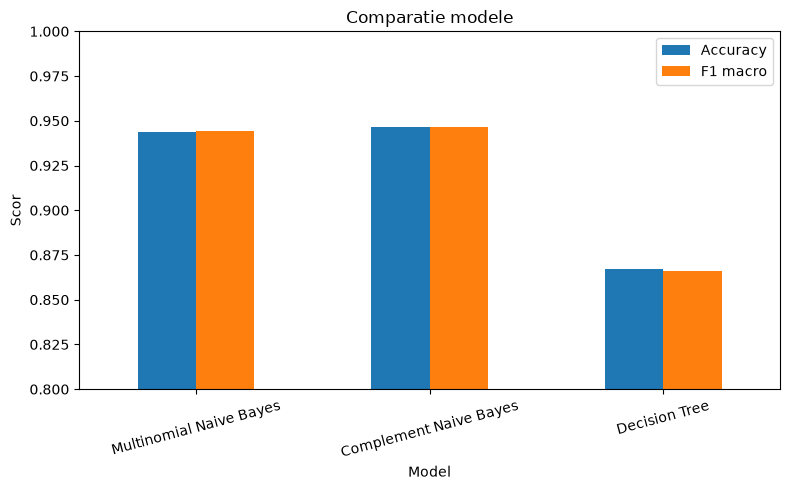

In [30]:
results_df[["Accuracy", "F1 macro"]].plot(kind="bar", figsize=(8, 5), ylim=(0.8, 1.0))
plt.title("Comparatie modele")
plt.ylabel("Scor")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

In [31]:
tree = models["Decision Tree"]
feature_names = vectorizer.get_feature_names_out()
top_idx = tree.feature_importances_.argsort()[::-1][:15]
print("\nTop 15 cuvinte/n-grame pentru Decision Tree:")
for i in top_idx:
    print(f"  {feature_names[i]:<25} {tree.feature_importances_[i]:.4f}")


Top 15 cuvinte/n-grame pentru Decision Tree:
  author                    0.1310
  women                     0.1002
  men                       0.0624
  usb                       0.0430
  camera                    0.0371
  book                      0.0345
  girls                     0.0315
  boys                      0.0249
  audio                     0.0231
  home                      0.0187
  steel                     0.0186
  kitchen                   0.0105
  black                     0.0104
  color                     0.0102
  set                       0.0094
